In [75]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

In [31]:
df = pd.read_csv('credit_risk_dataset.csv')
df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


<Axes: xlabel='person_age', ylabel='Count'>

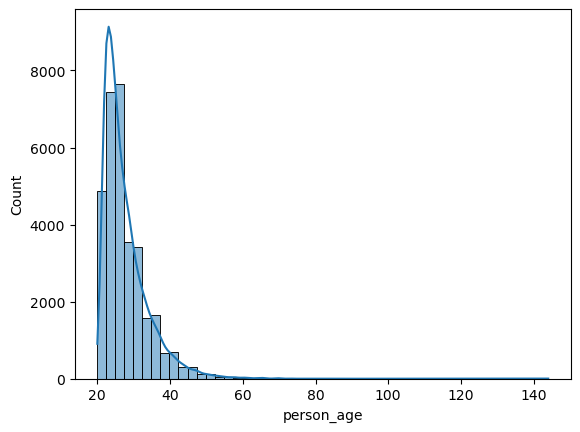

In [32]:
sns.histplot(df['person_age'], bins = 50, kde = True)

<Axes: ylabel='person_age'>

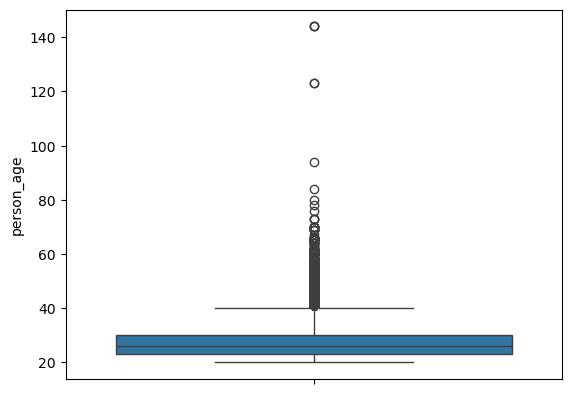

In [33]:
sns.boxplot(df['person_age'])

In [34]:
#df['person_age'].max() тут я решил проверить outliers, оказалось, что есть значения больше 100 (144, 123 и тд)
q1 = df['person_age'].quantile(0.25)
q3 = df['person_age'].quantile(0.75)

iqr = q3-q1
upper_border = q3+1.5*iqr
lower_border = q1-1.5*iqr

print(q1, q3, iqr, upper_border, lower_border)

23.0 30.0 7.0 40.5 12.5


1494 32581 4.585


<Axes: xlabel='person_age', ylabel='Count'>

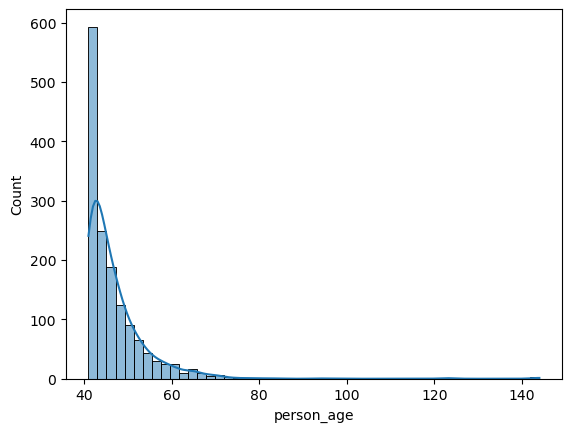

In [35]:
outliers = df[(df['person_age']>upper_border) | (df['person_age']<lower_border)]
print(len(outliers), len(df['person_age']), round(len(outliers)/len(df['person_age'])*100, 3))
#df['person_age'].sort_values(ascending=False).head(20)
sns.histplot(outliers['person_age'], bins = 50, kde = True)

In [36]:
outliers['person_age'].value_counts().sort_index()
#print((df['person_age']>100).sum()) всего пять значений больше сотни, хотя это и можно было увидеть визуально


person_age
41     241
42     188
43     164
44     141
45     108
46      94
47      94
48      75
49      49
50      52
51      39
52      36
53      30
54      24
55      20
56      15
57      15
58      19
59       5
60      15
61       9
62       7
63       3
64       7
65       9
66       9
67       1
69       5
70       7
73       3
76       1
78       1
80       1
84       1
94       1
123      2
144      3
Name: count, dtype: int64

In [37]:
df1 = df.copy()

In [38]:
def fix_age(person_age):
    if person_age >= 94:
        return 94
    else:
        return person_age

In [39]:
df1['person_age'] = df1['person_age'].apply(fix_age)

In [40]:
df1.max()
#видно, что person_emp_length ведет себя аномально

person_age                         94
person_income                 6000000
person_home_ownership            RENT
person_emp_length               123.0
loan_intent                   VENTURE
loan_grade                          G
loan_amnt                       35000
loan_int_rate                   23.22
loan_status                         1
loan_percent_income              0.83
cb_person_default_on_file           Y
cb_person_cred_hist_length         30
dtype: object

In [41]:
df1.groupby(pd.cut(df1['person_age'], bins=[0, 25, 35, 45, 55, 65, 75, 100]))['loan_status'].agg(['count', 'mean'])

/var/folders/fs/3wtwzm9n4sqdb8wjr4r8jbcm0000gn/T/ipykernel_28880/1300067037.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df1.groupby(pd.cut(df1['person_age'], bins=[0, 25, 35, 45, 55, 65, 75, 100]))['loan_status'].agg(['count', 'mean'])


,count,mean
person_age,,
"(0, 25]",15352,0.230263
"(25, 35]",13763,0.206786
"(35, 45]",2814,0.207178
"(45, 55]",513,0.218324
"(55, 65]",104,0.259615
"(65, 75]",25,0.200000
"(75, 100]",10,0.000000


In [42]:
df1.groupby(pd.cut(df1['person_age'], bins=[0, 25, 35, 45, 55, 65, 75, 100]))['loan_int_rate'].agg(['count', 'mean', 'median', 'min', 'max'])

/var/folders/fs/3wtwzm9n4sqdb8wjr4r8jbcm0000gn/T/ipykernel_28880/2350518532.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df1.groupby(pd.cut(df1['person_age'], bins=[0, 25, 35, 45, 55, 65, 75, 100]))['loan_int_rate'].agg(['count', 'mean', 'median', 'min', 'max'])


,count,mean,median,min,max
person_age,,,,,
"(0, 25]",13905,10.969802,10.99,5.42,22.11
"(25, 35]",12464,11.023724,10.99,5.42,22.48
"(35, 45]",2520,11.177667,11.12,5.42,23.22
"(45, 55]",452,11.028164,10.99,5.42,20.62
"(55, 65]",94,11.088617,10.99,5.42,18.64
"(65, 75]",22,11.178636,10.62,5.42,17.49
"(75, 100]",8,10.510000,10.98,7.51,13.57


In [43]:
#переходим к ставке loan_int_rate, мною было замечено, что есть пропуски NaN, осталось выяснить, что с ними делать
#df1[df1['loan_int_rate'].isnull()]
df1.groupby(pd.cut(df1['person_age'], bins=[0, 25, 35, 45, 55, 65, 75, 100]))['loan_int_rate'].agg(['count', 'mean', 'median', 'min', 'max'])

/var/folders/fs/3wtwzm9n4sqdb8wjr4r8jbcm0000gn/T/ipykernel_28880/1928660664.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df1.groupby(pd.cut(df1['person_age'], bins=[0, 25, 35, 45, 55, 65, 75, 100]))['loan_int_rate'].agg(['count', 'mean', 'median', 'min', 'max'])


,count,mean,median,min,max
person_age,,,,,
"(0, 25]",13905,10.969802,10.99,5.42,22.11
"(25, 35]",12464,11.023724,10.99,5.42,22.48
"(35, 45]",2520,11.177667,11.12,5.42,23.22
"(45, 55]",452,11.028164,10.99,5.42,20.62
"(55, 65]",94,11.088617,10.99,5.42,18.64
"(65, 75]",22,11.178636,10.62,5.42,17.49
"(75, 100]",8,10.510000,10.98,7.51,13.57


In [44]:
df1 = df1.dropna(subset = ['loan_int_rate']).copy()

In [45]:
#также ранее подмечал об экстремально большом опыте работы в person_emp_length
#df1[df1['person_emp_length'].notnull()].sort_values(by=['person_emp_length'], ascending=False)
#df1['person_emp_length'].sort_values(ascending=False)
#print((df1['person_emp_length'].isnull()).sum())

q1_person_emp_length = df1['person_emp_length'].quantile(0.25)
q3_person_emp_length = df1['person_emp_length'].quantile(0.75)

iqr_person_emp_length = q3_person_emp_length-q1_person_emp_length
upper_border_person_emp_length = q3_person_emp_length+1.5*iqr_person_emp_length
lower_border_person_emp_length = q1_person_emp_length-1.5*iqr_person_emp_length

print(q1_person_emp_length, q3_person_emp_length, iqr_person_emp_length, upper_border_person_emp_length, lower_border_person_emp_length)

2.0 7.0 5.0 14.5 -5.5


<Axes: ylabel='person_emp_length'>

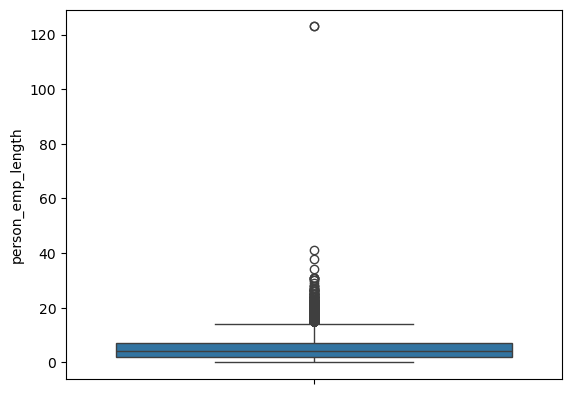

In [46]:
sns.boxplot(df['person_emp_length'])

In [47]:
#df1[df1['person_emp_length']>=df1['person_age']]
df1['diff'] = df1['person_age']-df1['person_emp_length']
#df1[df1['diff']>30]
# решил заменить аномальные значения 123 на среднее для этой же возрастной группы. кстати, среднее рассчитывал без учета 123 

mean_emp_length = df1.loc[(df1['person_age'] <= 25) & (df1['person_emp_length'] != 123), 'person_emp_length'].mean()
print(mean_emp_length)
#df1.groupby(pd.cut(df1['person_age'], bins=[0, 25, 35, 45, 55, 65, 75, 100]))['person_emp_length'].agg(['count', 'mean', 'median', 'max'])
df1.loc[df1['person_emp_length'] == 123, 'person_emp_length'] = round(mean_emp_length)

4.029230655093108


In [48]:
df1.sort_values(by=['person_emp_length'], ascending=False)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,diff
32355,78,48000,RENT,41.0,MEDICAL,A,3000,7.51,0,0.06,N,25,37.0
32515,53,106000,MORTGAGE,38.0,PERSONAL,B,20000,9.88,0,0.19,N,23,15.0
32428,58,49000,MORTGAGE,34.0,MEDICAL,D,7500,13.55,1,0.15,Y,24,24.0
30914,48,70000,MORTGAGE,31.0,HOMEIMPROVEMENT,D,9000,14.54,0,0.13,N,17,17.0
32263,46,180000,MORTGAGE,31.0,MEDICAL,B,18000,9.91,0,0.10,N,12,15.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32285,38,12000,OWN,NaN,EDUCATION,A,4800,7.29,1,0.40,N,12,NaN
32328,51,18408,RENT,NaN,PERSONAL,C,1000,14.65,1,0.05,Y,20,NaN
32360,70,39996,RENT,NaN,MEDICAL,C,3600,15.23,0,0.09,Y,19,NaN
32453,56,32400,RENT,NaN,MEDICAL,A,8575,7.51,0,0.26,N,18,NaN


In [49]:
#по параметру loan_amnt аномалий не обнаружил
#df1['loan_amnt'].value_counts()
#print((df1['loan_amnt'].isnull()).sum())
df1['loan_amnt'].sort_values()

15951      500
1355       500
871        500
8607       500
873        700
         ...  
10715    35000
12057    35000
14478    35000
17838    35000
0        35000
Name: loan_amnt, Length: 29465, dtype: int64

/var/folders/fs/3wtwzm9n4sqdb8wjr4r8jbcm0000gn/T/ipykernel_28880/4218128970.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df1.groupby(pd.cut(df1['person_age'], bins =[0, 25, 35, 45, 55, 65, 75, 100]))['loan_amnt'].agg(['mean'])


,mean
person_age,
"(0, 25]",9209.178353
"(25, 35]",9883.384146
"(35, 45]",10048.055556
"(45, 55]",10128.761062
"(55, 65]",10531.117021
"(65, 75]",9734.090909
"(75, 100]",8875.000000


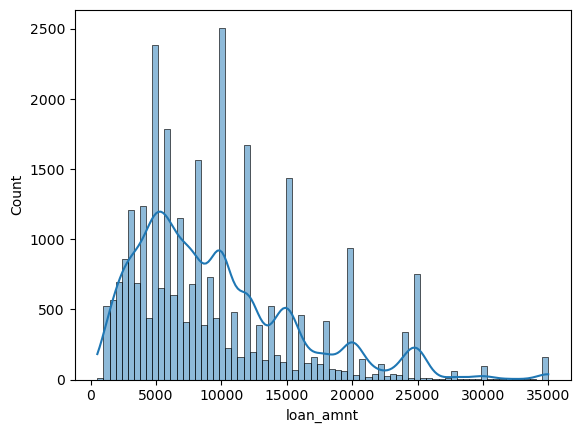

In [50]:
sns.histplot(df1['loan_amnt'], kde = True)
df1.groupby(pd.cut(df1['person_age'], bins =[0, 25, 35, 45, 55, 65, 75, 100]))['loan_amnt'].agg(['mean'])

In [51]:
#по параметру person_income аномалий анологично не обнаружил, единственное есть 1 наблюдение с 6 млн доходом
# и несвойственным для среднего этой возрастной группы
#df1['person_income'].value_counts()
#print((df1['loan_amnt'].isnull()).sum())
df1['person_income'].sort_values()
#df1['person_income'].describe()
#sns.histplot(df1['person_income'], bins= 50)
df1.groupby(pd.cut(df1['person_age'], bins=[0, 25, 35, 45, 55, 65, 75, 100]))['person_income'].agg(['count', 'mean', 'median', 'min', 'max'])

/var/folders/fs/3wtwzm9n4sqdb8wjr4r8jbcm0000gn/T/ipykernel_28880/4248322928.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df1.groupby(pd.cut(df1['person_age'], bins=[0, 25, 35, 45, 55, 65, 75, 100]))['person_income'].agg(['count', 'mean', 'median', 'min', 'max'])


,count,mean,median,min,max
person_age,,,,,
"(0, 25]",13905,59023.843653,52000.0,4080,500000
"(25, 35]",12464,70352.254814,59513.0,4200,1200000
"(35, 45]",2520,76331.140476,60000.0,4000,2039784
"(45, 55]",452,81010.663717,62023.5,8088,1362000
"(55, 65]",94,111397.648936,64500.0,9600,1782000
"(65, 75]",22,65528.909091,42000.0,24000,300000
"(75, 100]",8,851475.500000,87402.0,48000,6000000


<Axes: xlabel='person_income', ylabel='Count'>

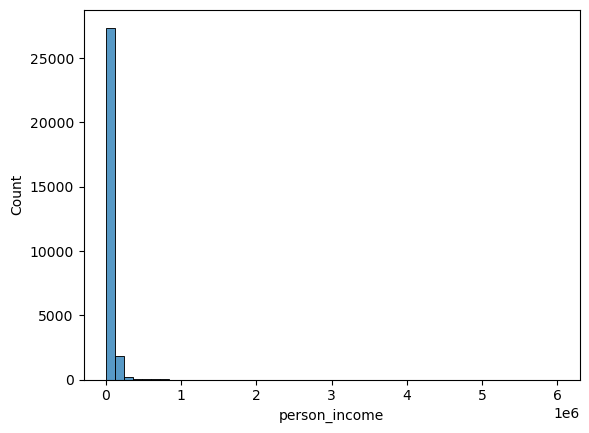

In [52]:
#проверка признака loan_percent_income
#df1['loan_percent_income']
#print((df1['loan_percent_income'].isnull()).sum())
#df1[df1['loan_percent_income']>0.99]
#df1.loc[df1['loan_percent_income']==0]
sns.histplot(df1['person_income'], bins = 50)

In [53]:
df1['calculated_ratio'] = round(df1['loan_amnt']/df1['person_income'], 2)
#df1[(df1['calculated_ratio']!=df1['loan_percent_income']) & (df1['loan_percent_income'] == 0)]
#выявил несоответствие расчетам у 915 наблюдений
df1['diff_in_percent'] = (df1['calculated_ratio']-df1['loan_percent_income']).abs()
df1.sort_values(by= 'diff_in_percent', ascending = False)
#разница доходит до 9 процентов
#df1[(df1['diff_in_percent'] > 0.02) & (df1['loan_status'] == 0)]
#все наблюдения, разницы которых превышают 2 пп, строго имеют loan status 1
df1[(df1['diff_in_percent'] > 0.02) & (df1['loan_status'] == 1)]
#есть гипотеза, что такая разница может возникать ввиду списания части дефолтных кредитов, от чего процент loan от income в итоге сократится
#решил оставить первоначальные loan_percent_income, так как не нашел убедительных объяснений от автора датасета

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,diff,calculated_ratio,diff_in_percent
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4,16.0,0.64,0.09
17,23,92111,RENT,7.0,MEDICAL,F,35000,20.25,1,0.32,N,4,16.0,0.38,0.06
40,26,62050,RENT,6.0,MEDICAL,E,30000,17.99,1,0.41,N,2,20.0,0.48,0.07
48,22,66300,RENT,4.0,MEDICAL,B,30000,12.69,1,0.38,N,3,18.0,0.45,0.07
202,24,56100,RENT,7.0,MEDICAL,D,25000,16.49,1,0.38,N,4,17.0,0.45,0.07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32131,44,51850,RENT,7.0,MEDICAL,D,10000,14.11,1,0.16,N,12,37.0,0.19,0.03
32183,46,88400,MORTGAGE,1.0,MEDICAL,E,30000,18.39,1,0.29,N,16,45.0,0.34,0.05
32256,38,59475,MORTGAGE,10.0,MEDICAL,D,18125,14.84,1,0.26,Y,13,28.0,0.30,0.04
32265,42,64464,MORTGAGE,13.0,MEDICAL,E,30000,19.03,1,0.40,N,14,29.0,0.47,0.07


In [54]:
print(df1.duplicated().sum())
print(df1.isna().sum())
df1 = df1.drop(columns=['diff'])

144
person_age                      0
person_income                   0
person_home_ownership           0
person_emp_length             827
loan_intent                     0
loan_grade                      0
loan_amnt                       0
loan_int_rate                   0
loan_status                     0
loan_percent_income             0
cb_person_default_on_file       0
cb_person_cred_hist_length      0
diff                          827
calculated_ratio                0
diff_in_percent                 0
dtype: int64


In [55]:
#обнаружил 144 полных дубликата, тк отсутствуют уникальные идентификаторы клиентов невозможно подтвердить, 
#являются ли совпадения техническими ошибками
df1 = df1.drop_duplicates().copy()
print(df1.shape)

(29321, 14)


In [56]:
#построение модели
X = df1[['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'cb_person_cred_hist_length']]
y = df1['loan_int_rate']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [57]:
#исправление NaN сначала на train, далее на test на median для избежания data leakage
X_train[X_train['person_emp_length'].isnull()]
median_emp = X_train['person_emp_length'].median()
print(median_emp)

4.0


In [58]:
X_train = X_train.copy()
X_train['person_emp_length'] = (X_train['person_emp_length'].fillna(median_emp))

In [59]:
X_test = X_test.copy()
X_test['person_emp_length'] = (X_test['person_emp_length'].fillna(median_emp))

In [60]:
y_train

28532     7.49
1964     12.21
29907     7.88
10317    10.65
30783    11.71
         ...  
23931     7.43
5944     13.22
960      11.71
17536     7.49
26220    14.84
Name: loan_int_rate, Length: 23456, dtype: float64

In [61]:
print((X_train['person_emp_length'].isnull()).sum())

0


In [62]:
model = LinearRegression()

In [63]:
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [64]:
test_predictions = model.predict(X_test)

In [65]:
test_predictions

array([ 9.85504791, 10.7828866 , 10.95462288, ..., 10.77881755,
       11.27465499, 11.40678063], shape=(5865,))

In [66]:
MAE = mean_absolute_error(y_test,test_predictions)
MSE = mean_squared_error(y_test,test_predictions)
RMSE = np.sqrt(MSE)

In [67]:
MAE

2.6878637720599197

In [68]:
MSE

10.414422670276794

In [69]:
RMSE

np.float64(3.227138464689235)

In [70]:
test_predictions = model.predict(X_test)

In [71]:
test_res = y_test - test_predictions

Text(0, 0.5, 'Residuals')

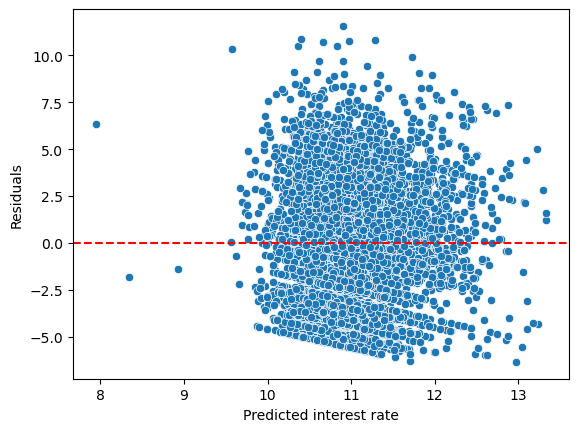

In [72]:
sns.scatterplot(x=test_predictions, y=test_res)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted interest rate')
plt.ylabel('Residuals')

In [73]:
print(model.intercept_)
print(pd.Series(model.coef_,index=X_train.columns))

10.409056848408316
person_age                    0.005542
person_income                -0.000002
person_emp_length            -0.057734
loan_amnt                     0.000082
cb_person_cred_hist_length    0.011924
dtype: float64


In [74]:
train_predictions = model.predict(X_train)

In [76]:
r2_train = r2_score(y_train, train_predictions)
r2_test = r2_score(y_test, test_predictions)

print('Train R²:', r2_train)
print('Test R²:', r2_test)

Train R²: 0.027548277571367463
Test R²: 0.031294448668373054


In [77]:
X_train_grade = X_train.copy()
X_test_grade = X_test.copy()

X_train_grade['loan_grade'] = df1.loc[X_train.index, 'loan_grade']
X_test_grade['loan_grade'] = df1.loc[X_test.index, 'loan_grade']

In [78]:
X_train_grade = pd.get_dummies(X_train_grade, columns=['loan_grade'], drop_first=True, dtype=int)
X_test_grade = pd.get_dummies(X_test_grade, columns=['loan_grade'], drop_first=True, dtype=int)

In [79]:
X_train_grade.head()

,person_age,person_income,person_emp_length,loan_amnt,cb_person_cred_hist_length,loan_grade_B,loan_grade_C,loan_grade_D,loan_grade_E,loan_grade_F,loan_grade_G
28532,27,90000,4.0,10000,9,0,0,0,0,0,0
1964,23,10000,1.0,2100,3,1,0,0,0,0,0
29907,48,92000,1.0,4800,17,0,0,0,0,0,0
10317,24,66600,3.0,7200,4,1,0,0,0,0,0
30783,37,45000,1.0,9000,12,1,0,0,0,0,0


In [80]:
X_test_grade = X_test_grade.reindex(columns=X_train_grade.columns, fill_value=0)

In [81]:
model_grade = LinearRegression()
model_grade.fit(X_train_grade, y_train)

train_predictions_grade = model_grade.predict(X_train_grade)
test_predictions_grade = model_grade.predict(X_test_grade)

In [82]:
print(r2_score(y_test, test_predictions_grade))
print(mean_absolute_error(y_test, test_predictions_grade))
print(np.sqrt(mean_squared_error(y_test, test_predictions_grade)))

0.9004526429355233
0.8035486613402922
1.0345144771328743


In [83]:
pd.Series(model_grade.coef_, index=X_train_grade.columns)

person_age                   -3.371656e-03
person_income                -1.828889e-07
person_emp_length            -3.783470e-03
loan_amnt                     5.759998e-06
cb_person_cred_hist_length    7.508264e-03
loan_grade_B                  3.663016e+00
loan_grade_C                  6.135145e+00
loan_grade_D                  8.023123e+00
loan_grade_E                  9.628870e+00
loan_grade_F                  1.118376e+01
loan_grade_G                  1.281457e+01
dtype: float64

In [84]:
test_res1 = y_test - test_predictions_grade

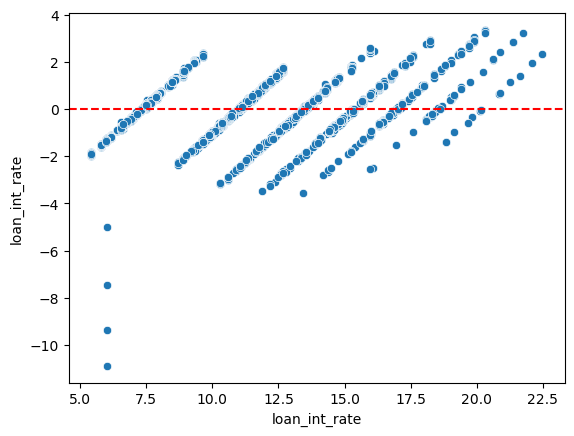

In [85]:
sns.scatterplot(x=y_test,y=test_res1)
plt.axhline(y=0, color='r', linestyle='--')

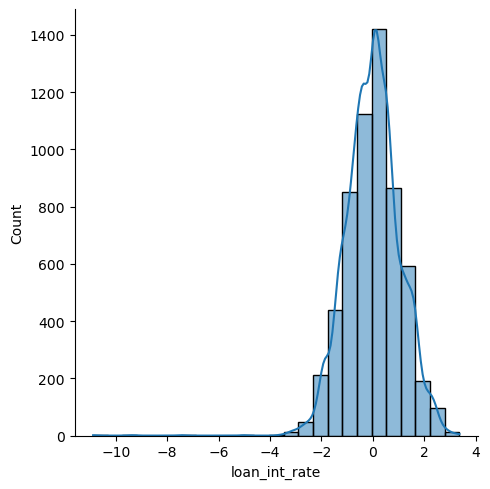

In [86]:
sns.displot(test_res1,bins=25,kde=True)